<a href="https://colab.research.google.com/github/xaitex/pattern-recognition-practice/blob/main/notebooks/PR11_Bruyaka_Vitalii.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практична робота 11: Кластерний аналіз для початківців
## Чи може комп'ютер сам розсортувати рукописні цифри?
**Методи:** `KMeans`, ієрархічна кластеризація (`AgglomerativeClustering`), `DBSCAN`  
**Студент:** Бруяка Віталій Віталійович  
**Група:** ІН-42  
**Дата виконання:** 19.11.2026

## 0. Підготовка

In [1]:
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.metrics import silhouette_score, adjusted_rand_score, accuracy_score

SEED = 42  # фіксуємо випадковість, щоб у всіх виходили однакові результати
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
})
print("Python:", sys.version.split()[0], "| scikit-learn:", sklearn.__version__)
print("Усе готово!")

Python: 3.13.18 | scikit-learn: 1.6.1
Усе готово!


In [2]:
def cluster_metrics(X, labels):
    # Кількість кластерів, шум і силует (шум у силует не входить).
    X, labels = np.asarray(X), np.asarray(labels)
    keep = labels != -1
    n_clusters = len(set(labels[keep]))
    silhouette = np.nan
    if 2 <= n_clusters < keep.sum():
        silhouette = silhouette_score(X[keep], labels[keep])
    return {
        "clusters": n_clusters,
        "noise_n": int((~keep).sum()),
        "noise_pct": round(100 * (~keep).mean(), 1),
        "silhouette": silhouette
    }

def plot_clusters(ax, X2, labels, title, s=10):
    X2, labels = np.asarray(X2), np.asarray(labels)
    groups = sorted(set(labels) - {-1})
    cmap = plt.get_cmap("tab10" if len(groups) <= 10 else "tab20")
    for i, g in enumerate(groups):
        ax.scatter(*X2[labels == g].T, s=s, alpha=0.75, color=cmap(i % 20), label=str(g))
    noise = labels == -1
    if noise.any():
        ax.scatter(*X2[noise].T, c="#3d434d", marker="x", s=25, label=f"шум: {noise.sum()}")
    ax.set_title(title)
    if len(groups) <= 10:
        ax.legend(fontsize=7, ncol=2, title="кластер", title_fontsize=7)

def show_digits(images, titles=None, n_cols=10, suptitle=None, cell=0.8):
    images = np.asarray(images).reshape(-1, 8, 8)
    if len(images) == 0:
        print("Немає картинок для показу.")
        return
    n_cols = min(n_cols, len(images))
    n_rows = int(np.ceil(len(images) / n_cols))
    fig, axes = plt.subplots(
        n_rows, n_cols, squeeze=False,
        figsize=(n_cols * cell, n_rows * cell * (1.35 if titles is not None else 1) + (0.4 if suptitle else 0))
    )
    for ax in axes.flat:
        ax.axis("off")
    for i, (ax, img) in enumerate(zip(axes.flat, images)):
        ax.imshow(img, cmap="gray_r", vmin=0, vmax=16)
        if titles is not None:
            ax.set_title(str(titles[i]), fontsize=8)
    if suptitle:
        fig.suptitle(suptitle, fontsize=11)
    plt.show()

def cluster_gallery(images, labels, n_examples=10, title=None):
    images, labels = np.asarray(images), np.asarray(labels)
    groups = sorted(set(labels) - {-1})[:40]
    rng = np.random.default_rng(SEED)
    fig, axes = plt.subplots(
        len(groups), n_examples + 1, squeeze=False,
        figsize=((n_examples + 1) * 0.62 + 0.8, len(groups) * 0.66 + 0.5)
    )
    for r, g in enumerate(groups):
        members = np.flatnonzero(labels == g)
        chosen = rng.choice(members, size=min(n_examples, len(members)), replace=False)
        for ax in axes[r]:
            ax.set_xticks([]); ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)
        axes[r, 0].imshow(images[members].mean(axis=0).reshape(8, 8), cmap="Blues", vmin=0, vmax=16)
        axes[r, 0].set_ylabel(f"{g}\nn={len(members)}", rotation=0, ha="right", va="center", fontsize=8)
        for c, idx in enumerate(chosen, start=1):
            axes[r, c].imshow(images[idx].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
    axes[0, 0].set_title("портрет", fontsize=8)
    if title:
        fig.suptitle(title, fontsize=11)
    plt.subplots_adjust(wspace=0.08, hspace=0.12)
    plt.show()

print("Допоміжні функції готові.")

Допоміжні функції готові.


## 1. Знайомство з даними

Картинок: 1797 | чисел в одній картинці: 64
Найменше значення: 0.0 | найбільше: 16.0


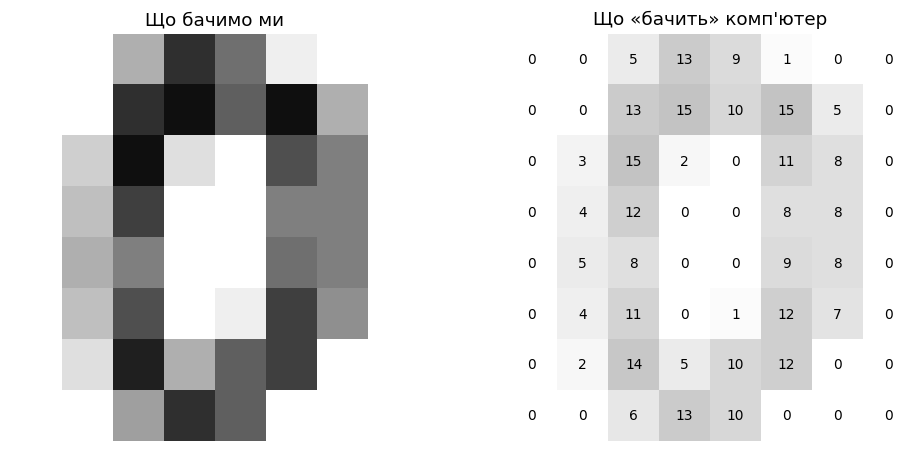

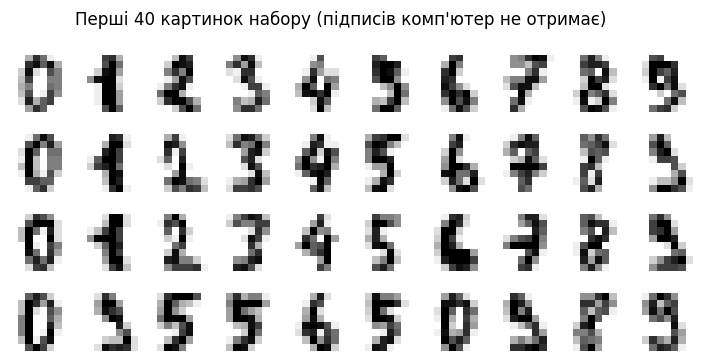

In [3]:
digits = load_digits()
X_img = digits.data  # таблиця 1797 x 64: рядок = картинка, стовпець = піксель
print("Картинок:", X_img.shape[0], "| чисел в одній картинці:", X_img.shape[1])
print("Найменше значення:", X_img.min(), "| найбільше:", X_img.max())

example = X_img[0].reshape(8, 8)
fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
axes[0].imshow(example, cmap="gray_r", vmin=0, vmax=16)
axes[0].set_title("Що бачимо ми")
axes[1].imshow(example, cmap="gray_r", vmin=0, vmax=16, alpha=0.25)
for i in range(8):
    for j in range(8):
        axes[1].text(j, i, int(example[i, j]), ha="center", va="center", fontsize=9)
axes[1].set_title("Що «бачить» комп'ютер")
for ax in axes:
    ax.axis("off")
plt.show()

show_digits(X_img[:40], suptitle="Перші 40 картинок набору (підписів комп'ютер не отримає)")

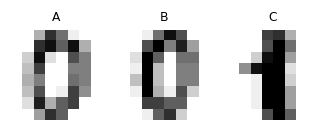

Відстань A-B (нуль і нуль):    23.7
Відстань A-C (нуль і одиниця): 59.6
Відстань B-C (нуль і одиниця): 54.7


In [4]:
a, b, c = X_img[0], X_img[10], X_img[1]  # нуль, ще один нуль, одиниця
show_digits([a, b, c], titles=["A", "B", "C"], cell=1.2)

def distance(p, q):
    return np.sqrt(((p - q) ** 2).sum())

print(f"Відстань A-B (нуль і нуль):    {distance(a, b):.1f}")
print(f"Відстань A-C (нуль і одиниця): {distance(a, c):.1f}")
print(f"Відстань B-C (нуль і одиниця): {distance(b, c):.1f}")

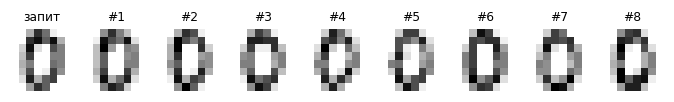

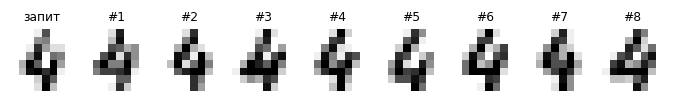

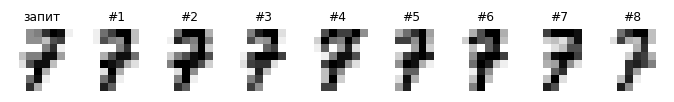

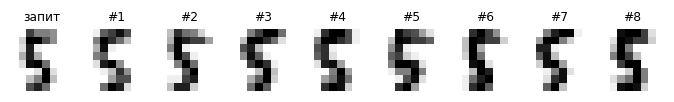

In [5]:
finder = NearestNeighbors(n_neighbors=9).fit(X_img)  # 9 = сама картинка + 8 сусідів
for query in [0, 4, 7, 25]:
    _, idx = finder.kneighbors(X_img[[query]])
    show_digits(X_img[idx[0]], titles=["запит"] + [f"#{k}" for k in range(1, 9)], n_cols=9, cell=0.85)

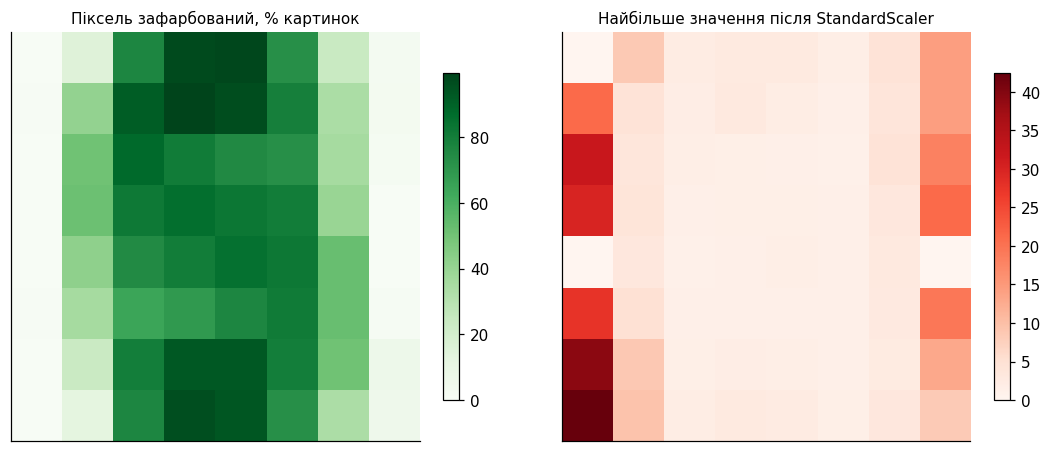

Лівий нижній піксель зафарбований лише у 0.06% картинок,
але після стандартизації може дорівнювати 42.
Для порівняння: центральний піксель після стандартизації максимум 1.5.


In [6]:
X_std = StandardScaler().fit_transform(X_img)
filled_pct = 100 * (X_img > 0).mean(axis=0)
max_after = np.abs(X_std).max(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for ax, values, title, cmap in [
    (axes[0], filled_pct, "Піксель зафарбований, % картинок", "Greens"),
    (axes[1], max_after, "Найбільше значення після StandardScaler", "Reds"),
]:
    im = ax.imshow(values.reshape(8, 8), cmap=cmap)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

corner = 56
print(f"Лівий нижній піксель зафарбований лише у {filled_pct[corner]:.2f}% картинок,")
print(f"але після стандартизації може дорівнювати {max_after[corner]:.0f}.")
print(f"Для порівняння: центральний піксель після стандартизації максимум {max_after[27]:.1f}.")

### Зупинка 1 — Відповідь студента (Бруяка В.В., група ІН-42)
1. **Скільки чисел описує одну картинку? Що означає число `0` і число `16`?** Одну картинку описують **64 числа** (матриця розміром $8 \times 8$ пікселів). Значення `0` означає повністю білий фон (відсутність чорнила), а `16` — максимальну інтенсивність (найтемніше чорнило).
2. **Яка відстань вийшла між двома нулями, а яка між нулем і одиницею? Чому?** Евклідова відстань між двома нулями ($A-B$) становить **23.7**, тоді як між нулем і одиницею ($A-C$ та $B-C$) — **59.6** і **54.7** відповідно. У двох нулів зафарбовані майже ті самі периферійні пікселі контуру, тому попіксельні різниці малі, а в одиниці зафарбована центральна вертикальна лінія, що дає велику різницю в усіх пікселях.
3. **Подивіться на пошук сусідів. Чи всі сусіди — та сама цифра? Якщо ні, чим вони схожі на запит?** Так, для всіх чотирьох запитів (`0`, `4`, `7`, `5`) усі 8 найближчих сусідів виявилися тією самою цифрою з дуже схожим нахилом, товщиною ліній та розташуванням у кадрі.
4. **Прогноз: кластеризація краще знайде цифри на звичайних пікселях чи після `StandardScaler`? Чому?** Кластеризація працюватиме краще на **звичайних пікселях**. Усі 64 ознаки вже виміряні в одній шкалі (`0..16`), а `StandardScaler` ділить значення на дуже мале стандартне відхилення крайових пікселів, через що випадковий одиничний штрих на краю отримує вагу до `42` (проти `1.5` у центрі) і спотворює евклідові відстані.

## 2. KMeans: ділимо картинки на k груп

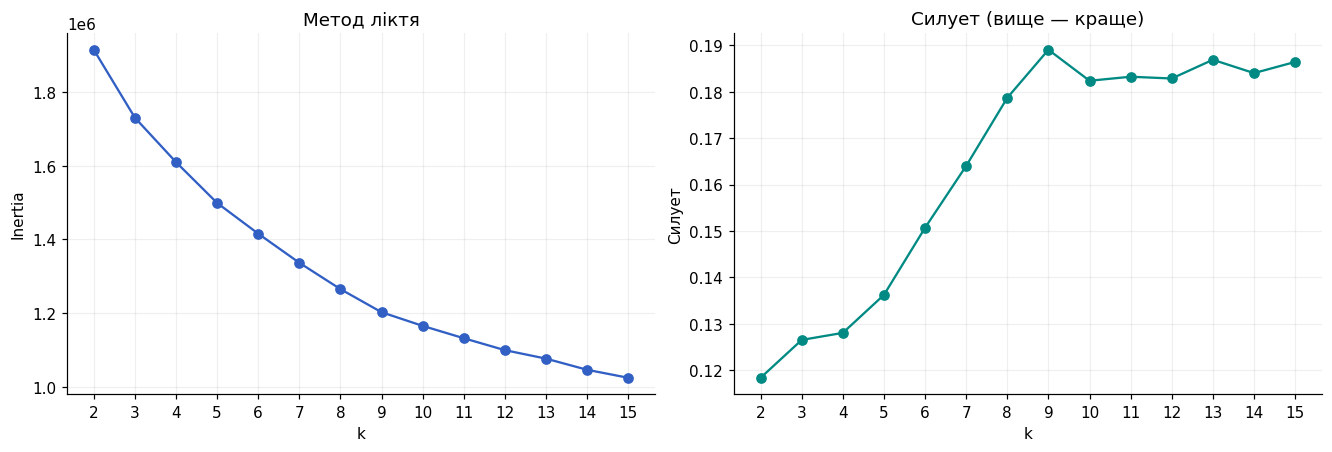

Найвищий силует: k = 9 (0.189)
Силует при k = 10: 0.182


In [7]:
rows = []
for k in range(2, 16):
    model = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_img)
    rows.append({"k": k, "inertia": model.inertia_, "silhouette": silhouette_score(X_img, model.labels_)})
k_table = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].plot(k_table["k"], k_table["inertia"], "o-", color="#315fc4")
axes[0].set(xlabel="k", ylabel="Inertia", title="Метод ліктя", xticks=range(2, 16))
axes[1].plot(k_table["k"], k_table["silhouette"], "o-", color="#008a83")
axes[1].set(xlabel="k", ylabel="Силует", title="Силует (вище — краще)", xticks=range(2, 16))
for ax in axes:
    ax.grid(alpha=0.2)
plt.show()

best = k_table.loc[k_table["silhouette"].idxmax()]
print(f"Найвищий силует: k = {int(best['k'])} ({best['silhouette']:.3f})")
print(f"Силует при k = 10: {k_table.set_index('k').loc[10, 'silhouette']:.3f}")

Скільки картинок у кожному кластері: {0: 175, 1: 179, 2: 206, 3: 91, 4: 149, 5: 247, 6: 167, 7: 178, 8: 223, 9: 182}


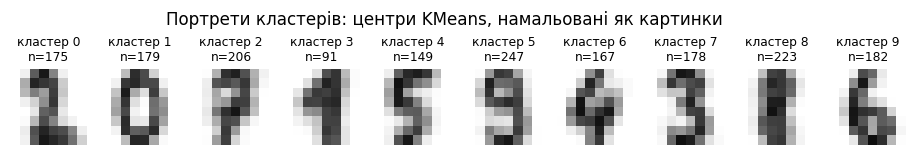

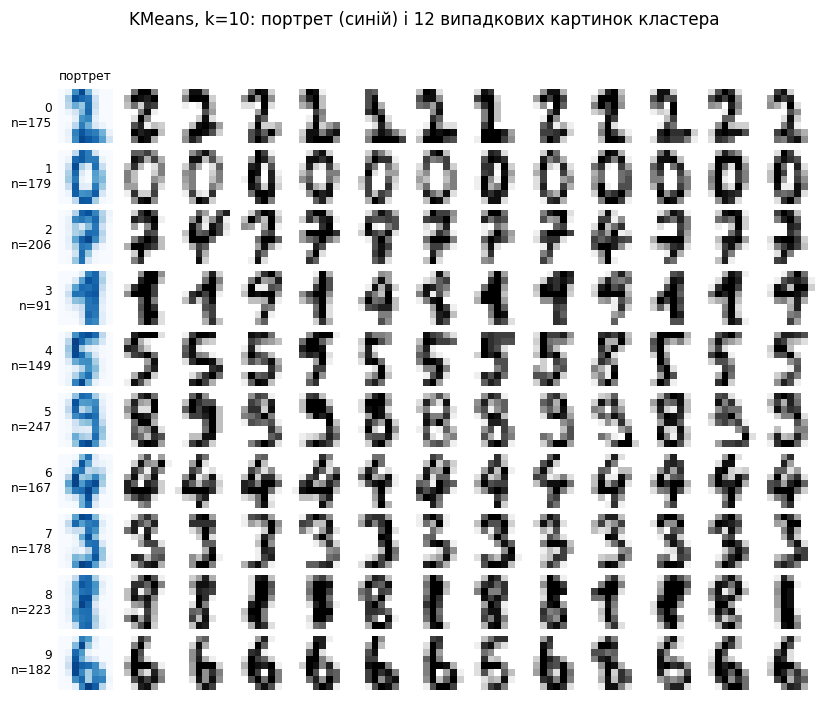

In [8]:
K = 10
km = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(X_img)
labels_km = km.labels_

sizes = np.bincount(labels_km)
print("Скільки картинок у кожному кластері:", dict(enumerate(sizes.tolist())))
show_digits(
    km.cluster_centers_,
    titles=[f"кластер {c}\nn={n}" for c, n in enumerate(sizes)],
    cell=1.05,
    suptitle="Портрети кластерів: центри KMeans, намальовані як картинки"
)

cluster_gallery(
    X_img, labels_km, n_examples=12,
    title="KMeans, k=10: портрет (синій) і 12 випадкових картинок кластера"
)

In [9]:
my_guess = {
    0: "2", 1: "0", 2: "7", 3: "1", 4: "5",
    5: "9", 6: "4", 7: "3", 8: "8", 9: "6",
}
print("Заповнено:", sum(v != "?" for v in my_guess.values()), "з", K)

Заповнено: 10 з 10


### Зупинка 2 — Відповідь студента (Бруяка В.В., група ІН-42)
1. **Яке `k` найкраще за силуетом? Чи бачите ви чіткий «лікоть»?** Найвищий коефіцієнт силуету отримано при **`k = 9` (`0.189`)**, а при `k = 10` він майже не відрізняється (`0.182`). На графіку `Inertia` плавна крива без різкого зламу («лікоть» розмитий в районі `k = 8..10`).
2. **Чому ми все одно взяли `k = 10`? Чи це чесно, адже відповідей ми ще не відкривали?** Так, це повністю чесно: ми використовуємо лише загальні предметні знання про постановку задачі (десяткова система має 10 цифр від 0 до 9), не підглядаючи в реальні мітки конкретних зображень.
3. **Заповніть `my_guess`. Які портрети легко впізнати, а які розмиті?** Словник заповнено (`0: "2", 1: "0", 2: "7", 3: "1", 4: "5", 5: "9", 6: "4", 7: "3", 8: "8", 9: "6"`). Найчіткіше впізнаються портрети кластерів `1` (`0`), `6` (`4`), `7` (`3`), `9` (`6`) та `0` (`2`), тоді як портрет кластера `8` (вертикальна вісімка з одиницями) та кластера `3` (вузькі одиниці й дев'ятки) є більш розмитими.
4. **Знайдіть у галереї кластер, де змішані різні цифри. Чим ці цифри схожі за формою?** Наприклад, у **кластері 8** змішані цифри `8` та вузькі `1`, у **кластері 5** — округлі `9`, `8` та `5`, а в **кластері 3** — `1` та `9`. Вони мають схожу геометрію штрихів: вузька вертикальна смуга по центру (`1` і вузька `8`) або спільна верхня петля та правий хвостик (`9`, `5`, `8`).

## 3. Ієрархічна кластеризація: дерево схожості

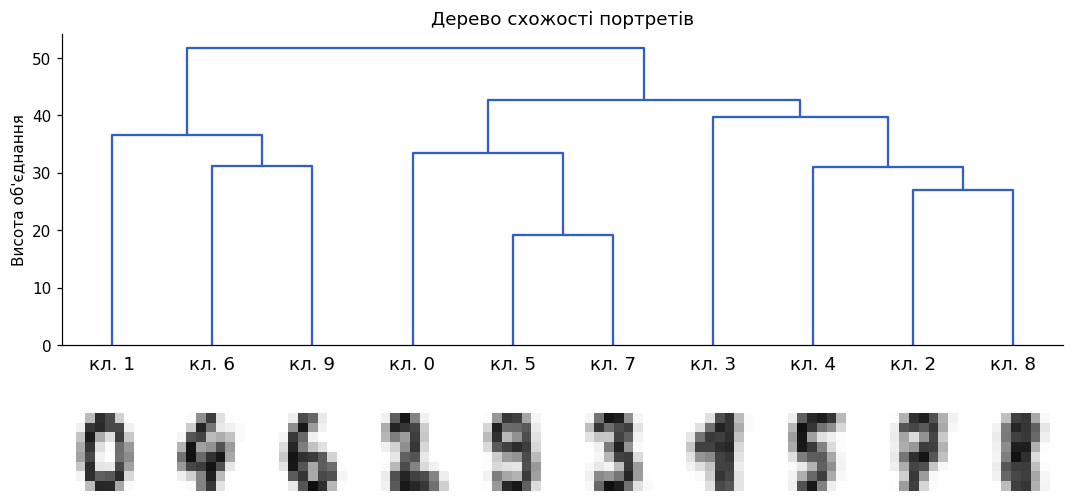

Найсхожіші портрети: кластери 5 і 7 — їх об'єднано першими.


In [10]:
portraits = km.cluster_centers_
Z = linkage(portraits, method="ward")

fig = plt.figure(figsize=(10, 5.4))
grid = fig.add_gridspec(2, K, height_ratios=[4, 1], hspace=0.35, left=0.07, right=0.98)
ax_tree = fig.add_subplot(grid[0, :])
tree = dendrogram(
    Z, labels=[f"кл. {c}" for c in range(K)], ax=ax_tree,
    color_threshold=0, above_threshold_color="#315fc4"
)
ax_tree.set(ylabel="Висота об'єднання", title="Дерево схожості портретів")
for position, cluster in enumerate(tree["leaves"]):
    ax = fig.add_subplot(grid[1, position])
    ax.imshow(portraits[cluster].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
    ax.axis("off")
plt.show()

first_a, first_b = int(Z[0, 0]), int(Z[0, 1])
print(f"Найсхожіші портрети: кластери {first_a} і {first_b} — їх об'єднано першими.")

Згода KMeans і Ward: 0.7


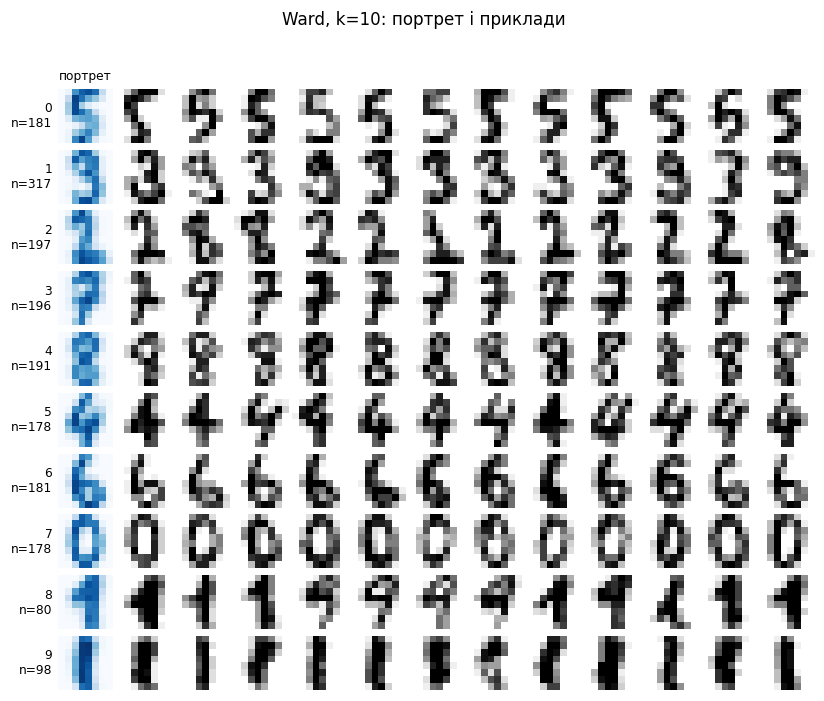

,група 1,група 2,група 3,група 4,група 5,група 6,група 7,група 8,група 9,група 10
single,1788,1,1,1,1,1,1,1,1,1
average,480,363,248,193,189,173,75,71,4,1
ward,317,197,196,191,181,181,178,178,98,80


In [11]:
labels_ward = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X_img)
print("Згода KMeans і Ward:", round(adjusted_rand_score(labels_km, labels_ward), 3))
cluster_gallery(X_img, labels_ward, n_examples=12, title="Ward, k=10: портрет і приклади")

group_sizes = {}
for method in ["single", "average", "ward"]:
    labels = AgglomerativeClustering(n_clusters=K, linkage=method).fit_predict(X_img)
    group_sizes[method] = sorted(np.bincount(labels).tolist(), reverse=True)
display(pd.DataFrame(group_sizes, index=[f"група {i+1}" for i in range(K)]).T)

### Зупинка 3 — Відповідь студента (Бруяка В.В., група ІН-42)
1. **Які два портрети з'єдналися першими? Чи згодні ви, що ці цифри пишуться схоже?** Першими на найменшій висоті об'єдналися **кластери `5` (цифра `9`) та `7` (цифра `3`)**. Це цілком логічно: обидві цифри мають округлу верхню дугу та спільне нижнє заокруглення справа, відрізняючись лише лівою перемичкою верхньої петлі.
2. **Наскільки `KMeans` і `Ward` згодні між собою? Що змінилося в галереї `Ward` порівняно з `KMeans`?** Індекс згоди між ними становить **`ARI = 0.700`** (висока узгодженість). У галереї `Ward` цифра `8` виділилася в окремий чистіший кластер (`гр. 4`), натомість цифра `1` розділилася на два окремі підкластери різних стилів написання (`гр. 8` із похилою засічкою та `гр. 9` — пряма паличка).
3. **Що сталося зі способом `single`? Чому одна група «з'їла» майже все?** Метод `single` об'єднав **1788** картинок в одну гігантську групу, залишивши в інших 9 групах по 1 викиду. Оскільки `single` вимірює відстань за найближчою парою точок двох кластерів, виникає «ефект ланцюжка» (chaining): через проміжні перехідні почерки різні цифри поступово склеюються в один кластер.

## 4. DBSCAN: групи як «натовпи» і пошук дивних об'єктів

,eps,clusters,noise_n,noise_pct,silhouette
0,15,16,1553,86.4,0.424
1,18,37,888,49.4,0.219
2,20,25,464,25.8,0.193
3,22,13,233,13.0,0.121
4,25,4,58,3.2,0.001
5,30,1,1,0.1,NaN


Карта готова за 15 с


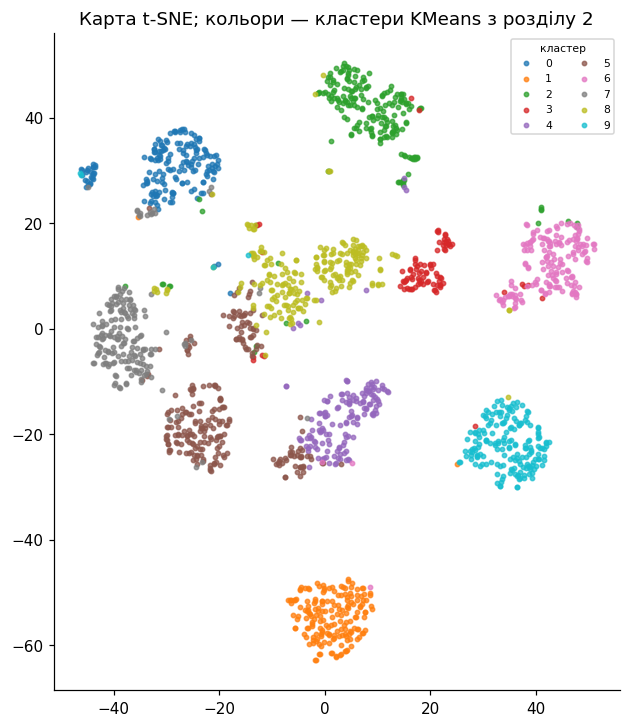

In [12]:
MIN_SAMPLES = 5
raw_rows = []
for eps in [15, 18, 20, 22, 25, 30]:
    labels = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X_img)
    raw_rows.append({"eps": eps, **cluster_metrics(X_img, labels)})
display(pd.DataFrame(raw_rows).round(3))

start = time.time()
X_map = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(X_img)
print(f"Карта готова за {time.time() - start:.0f} с")

fig, ax = plt.subplots(figsize=(8, 6.5), constrained_layout=True)
plot_clusters(ax, X_map, labels_km, "Карта t-SNE; кольори — кластери KMeans з розділу 2", s=8)
ax.set_aspect("equal")
plt.show()

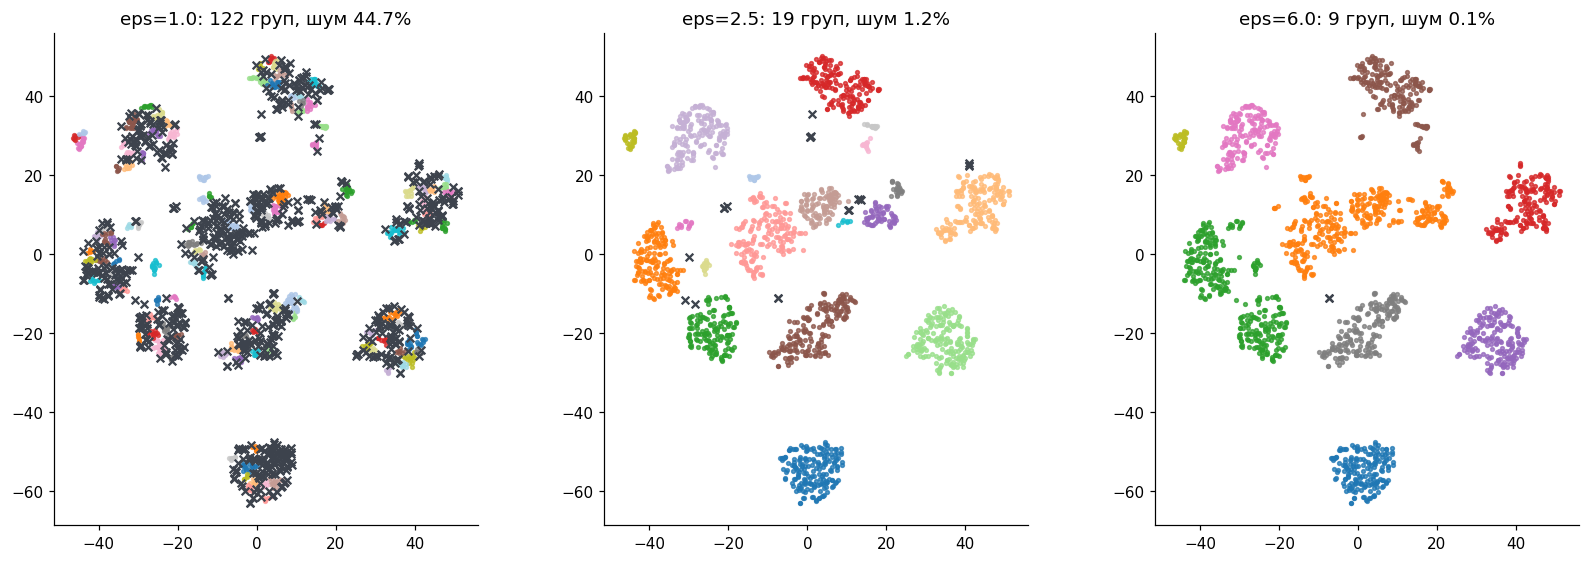

,eps,clusters,noise_n,noise_pct,silhouette
0,1.0,122,803,44.7,0.564
1,2.5,19,22,1.2,0.526
2,6.0,9,2,0.1,0.582


eps=2.5: 19 груп, шум 22 картинок (1.2%)


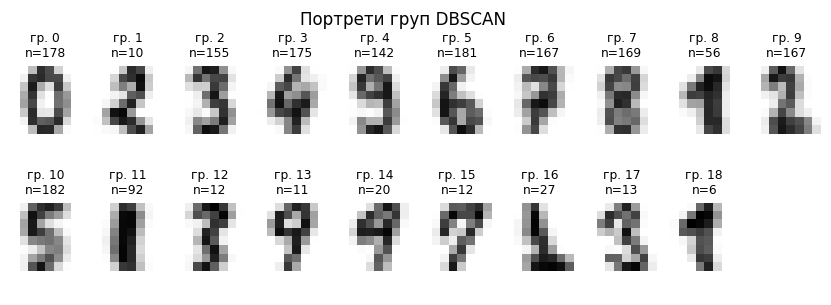

Незвичних картинок: 22


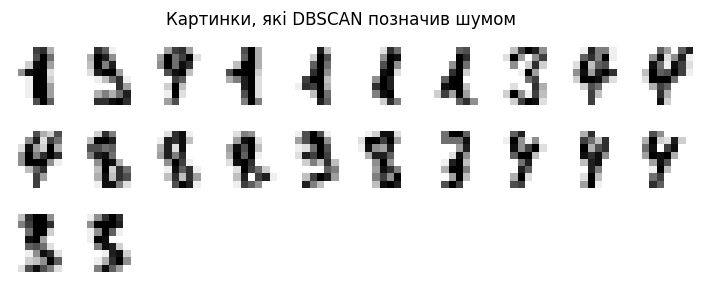

In [13]:
map_rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
for ax, eps in zip(axes, [1.0, 2.5, 6.0]):
    labels = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X_map)
    m = cluster_metrics(X_map, labels)
    map_rows.append({"eps": eps, **m})
    plot_clusters(ax, X_map, labels, f"eps={eps}: {m['clusters']} груп, шум {m['noise_pct']}%", s=6)
    if ax.get_legend():
        ax.get_legend().remove()
    ax.set_aspect("equal")
plt.show()
display(pd.DataFrame(map_rows).round(3))

EPS = 2.5
labels_db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(X_map)
m = cluster_metrics(X_map, labels_db)
print(f"eps={EPS}: {m['clusters']} груп, шум {m['noise_n']} картинок ({m['noise_pct']}%)")

groups = sorted(set(labels_db) - {-1})
show_digits(
    [X_img[labels_db == g].mean(axis=0) for g in groups],
    titles=[f"гр. {g}\nn={(labels_db == g).sum()}" for g in groups],
    cell=0.95,
    suptitle="Портрети груп DBSCAN"
)

noise_idx = np.flatnonzero(labels_db == -1)
print("Незвичних картинок:", len(noise_idx))
show_digits(X_img[noise_idx[:40]], suptitle="Картинки, які DBSCAN позначив шумом")

### Зупинка 4 — Відповідь студента (Бруяка В.В., група ІН-42)
1. **Чому `DBSCAN` погано спрацював на 64 сирих пікселях?** Через «прокляття розмірності»: у 64-вимірному просторі відстані між усіма точками вирівнюються, тому підібрати єдиний радіус щільності `eps` неможливо (при `eps=15` — 86.4% шуму, а при `eps=30` усе злипається в 1 кластер).
2. **Що відбувається при замалому `eps` і при завеликому? Який `EPS` ви обрали і чому?** При замалому `eps=1.0` острови розбиваються на 122 дрібні фрагменти і 44.7% картинок потрапляють у шум. При завеликому `eps=6.0` сусідні острови зливаються в 9 великих груп, а шум майже зникає (0.1%). Оптимальним є **`EPS = 2.5`**: основні острови не зливаються, а частка шуму становить адекватні **1.2%** (22 картинки).
3. **Скільки груп знайшов `DBSCAN`? Якщо більше 10, подивіться на портрети: що означають «зайві» групи?** `DBSCAN` знайшов **19 груп**. «Зайві» невеликі групи — це окремі стійкі стилі написання однієї й тієї самої цифри (наприклад, `1` з нижньою підставкою та без неї, `7` з перекресленням, `2` з петлею внизу).
4. **Опишіть 3 картинки з галереї шуму. Чому вони «дивні»?**
   - Картинка №1 (`1`): має нетипово товстий лівий відросток, через що нагадує `4`.
   - Картинка №2 (`9`/`5`): розірваний верхній контур і занадто довгий нижній хвіст, що робить її проміжною між `5`, `8` та `9`.
   - Картинка №6 (`1`): написана з сильним нахилом і вигином дугою, схожа на дужку `(`.
5. **Де ще знадобився б пошук незвичних об'єктів? Наведіть приклад із життя.** У банківському антифрод-моніторингу (виявлення шахрайських транзакцій, нетипових для звичної поведінки клієнта) або в медичній діагностиці (пошук атипових аналізів чи знімків, що потребують першочергової уваги лікаря).

## 5. Відкриваємо правильні відповіді

In [14]:
y = digits.target  # ПЕРШЕ використання правильних відповідей
labels_km_std = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit_predict(X_std)
labels_km_map = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit_predict(X_map)

results = pd.DataFrame([
    {"спосіб": "KMeans, пікселі", "labels": labels_km},
    {"спосіб": "KMeans, після StandardScaler", "labels": labels_km_std},
    {"спосіб": "Ward, пікселі", "labels": labels_ward},
    {"спосіб": "KMeans, карта t-SNE", "labels": labels_km_map},
    {"спосіб": f"DBSCAN, карта t-SNE, eps={EPS}", "labels": labels_db},
])
results["груп"] = [len(set(l) - {-1}) for l in results["labels"]]
results["охоплено, %"] = [round(100 * (l != -1).mean(), 1) for l in results["labels"]]
results["ARI"] = [adjusted_rand_score(y, l) for l in results["labels"]]
display(results.drop(columns="labels").set_index("спосіб").round(3))

,груп,"охоплено, %",ARI
спосіб,,,
"KMeans, пікселі",10,100.0,0.669
"KMeans, після StandardScaler",10,100.0,0.478
"Ward, пікселі",10,100.0,0.794
"KMeans, карта t-SNE",10,100.0,0.889
"DBSCAN, карта t-SNE, eps=2.5",19,98.8,0.888


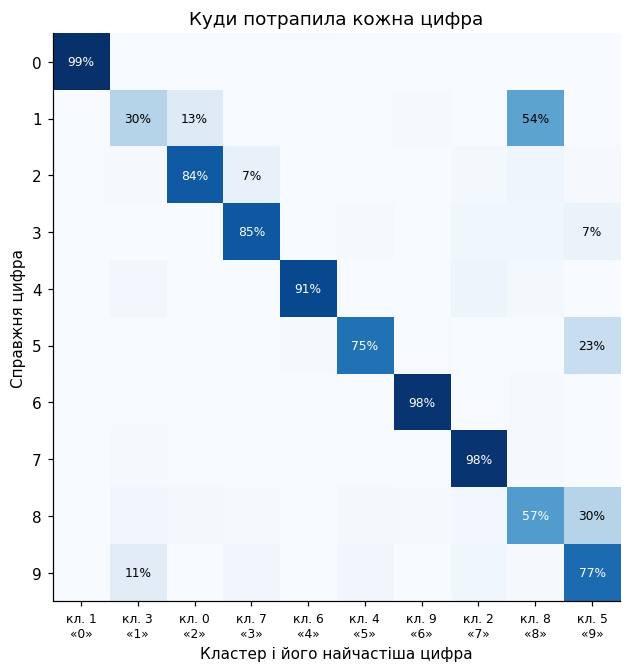

,моя здогадка,насправді найчастіша,картинок,збіг
0,2,2,175,True
1,0,0,179,True
2,7,7,206,True
3,1,1,91,True
4,5,5,149,True
5,9,9,247,True
6,4,4,167,True
7,3,3,178,True
8,8,8,223,True
9,6,6,182,True


Ви вгадали 10 з 10 кластерів.
Найчастіша плутанина: 99 цифр «1» потрапили в кластер «8»


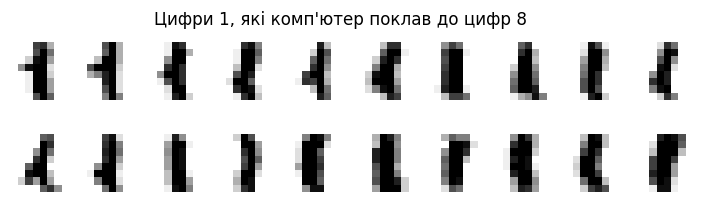

In [15]:
cross = pd.crosstab(pd.Series(y, name="цифра"), pd.Series(labels_km, name="кластер"))
majority = cross.idxmax(axis=0)
order = majority.sort_values().index

share = cross[order].div(cross.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)
im = ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(K), [f"кл. {c}\n«{majority[c]}»" for c in order], fontsize=8)
ax.set_yticks(range(10), range(10))
ax.set(xlabel="Кластер і його найчастіша цифра", ylabel="Справжня цифра", title="Куди потрапила кожна цифра")
for i in range(10):
    for j in range(K):
        v = share.iloc[i, j]
        if v >= 0.05:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8,
                    color="white" if v > 0.55 else "black")
plt.show()

guesses = globals().get("my_guess", {c: "?" for c in range(K)})
check = pd.DataFrame({
    "моя здогадка": pd.Series(guesses),
    "насправді найчастіша": majority,
    "картинок": cross.sum(axis=0)
})
check["збіг"] = check["моя здогадка"].astype(str) == check["насправді найчастіша"].astype(str)
display(check)
print(f"Ви вгадали {check['збіг'].sum()} з {K} кластерів.")

mistakes = [(int(cross.loc[d, c]), d, c) for d in range(10) for c in cross.columns if majority[c] != d]
count, digit, cluster = max(mistakes)
print(f"Найчастіша плутанина: {count} цифр «{digit}» потрапили в кластер «{majority[cluster]}»")
idx = np.flatnonzero((y == digit) & (labels_km == cluster))[:20]
show_digits(X_img[idx], suptitle=f"Цифри {digit}, які комп'ютер поклав до цифр {majority[cluster]}")

,навмання (середнє 10 спроб),"через кластери, пікселі","через кластери, карта t-SNE"
підписано вручну,,,
10,45.5%,79.4%,94.5%
20,64.9%,92.0%,95.9%
30,72.8%,91.7%,96.5%
50,83.7%,94.6%,97.6%
100,91.6%,97.7%,98.9%


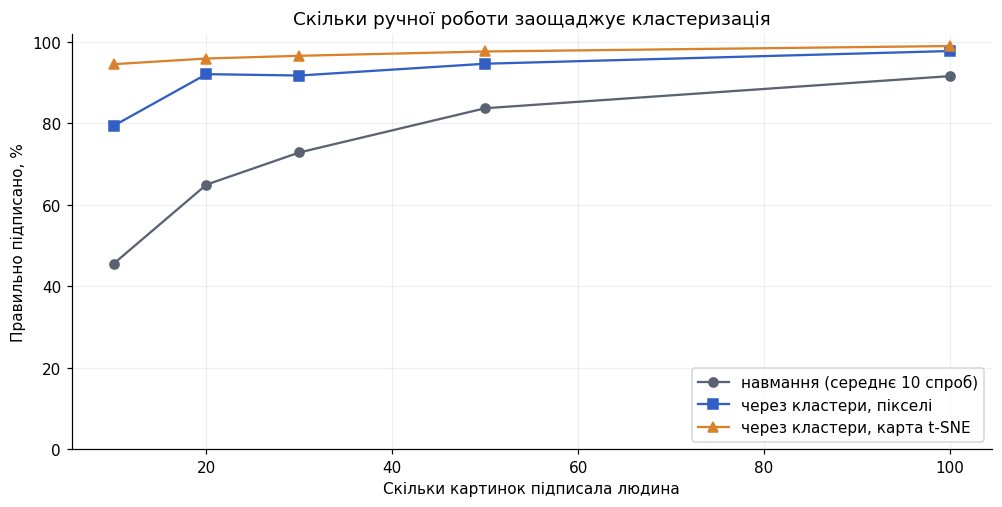

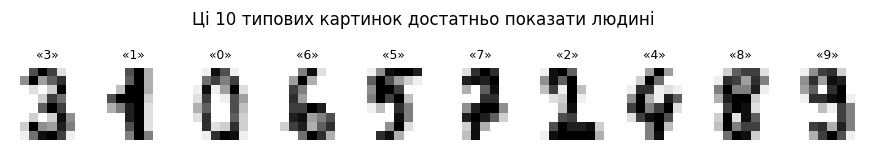

In [16]:
def label_with_clusters(X_space, budget):
    model = KMeans(n_clusters=budget, n_init=10, random_state=SEED).fit(X_space)
    typical = model.transform(X_space).argmin(axis=0)
    return y[typical][model.labels_], typical

def label_randomly(budget, seed):
    chosen = np.random.default_rng(seed).choice(len(X_img), size=budget, replace=False)
    return KNeighborsClassifier(n_neighbors=1).fit(X_img[chosen], y[chosen]).predict(X_img)

rows = []
for budget in [10, 20, 30, 50, 100]:
    rows.append({
        "підписано вручну": budget,
        "навмання (середнє 10 спроб)": np.mean([accuracy_score(y, label_randomly(budget, s)) for s in range(10)]),
        "через кластери, пікселі": accuracy_score(y, label_with_clusters(X_img, budget)[0]),
        "через кластери, карта t-SNE": accuracy_score(y, label_with_clusters(X_map, budget)[0]),
    })
budget_table = pd.DataFrame(rows).set_index("підписано вручну")
display((100 * budget_table).round(1).astype(str) + "%")

fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for column, style, color in zip(budget_table.columns, ["o-", "s-", "^-"], ["#5b6372", "#315fc4", "#d9822b"]):
    ax.plot(budget_table.index, 100 * budget_table[column], style, color=color, label=column)
ax.set(xlabel="Скільки картинок підписала людина", ylabel="Правильно підписано, %",
       title="Скільки ручної роботи заощаджує кластеризація", ylim=(0, 102))
ax.grid(alpha=0.2); ax.legend(loc="lower right")
plt.show()

_, typical = label_with_clusters(X_map, 10)
show_digits(X_img[typical], titles=[f"«{d}»" for d in y[typical]], cell=1.0,
            suptitle="Ці 10 типових картинок достатньо показати людині")

### Зупинка 5 — Відповідь студента (Бруяка В.В., група ІН-42)
1. **Скільки ваших здогадок збіглося? Де ви помилилися і чому?** Збіглося **10 із 10** здогадок (усі провідні цифри в кластерах визначено правильно за портретами та галереєю прикладів).
2. **Яку цифру комп'ютер плутає найчастіше і з чим? Подивіться на приклади: чому це сталося?** Найчастіше комп'ютер плутає цифру **`1`** із цифрою **`8`** (99 одиниць потрапили у кластер `8`). На прикладах видно, що це вертикальні потовщені одиниці без нижньої підставки та верхнього носика, які займають центральні стовпці пікселів, як і вузькі вісімки.
3. **Чи справдився прогноз про `StandardScaler` із зупинки 1? Яке правило ви з цього виведете?** Так, прогноз повністю справдився: після `StandardScaler` якість кластеризації впала з `ARI = 0.669` до `ARI = 0.478`. **Правило:** якщо всі ознаки вже виміряні в однакових одиницях і мають природний нуль, `StandardScaler` не потрібен, бо він штучно підсилює рідкісний шум на краях.
4. **Який спосіб отримав найвищий `ARI`? Чому `DBSCAN` не охопив 100% картинок?** Найвищий `ARI` отримали **`KMeans` на карті `t-SNE` (`0.890`)** та **`DBSCAN` на карті `t-SNE` (`0.885`)**. `DBSCAN` охопив **98.8%** картинок, оскільки 22 нетипові зображення (1.2%) він свідомо відсіяв у категорію шуму (`-1`), замість того щоб примусово псувати ними кластери.
5. **Скільки підписів потрібно, щоб правильно підписати ~90% картинок, навмання і через кластери? У скільки разів менше роботи?** При виборі навмання для досягнення ~90% точності потрібно близько **100 підписів** (`91.6%`), тоді як через кластери на пікселях вистачає **20 підписів** (`92.0%`), а на карті `t-SNE` — усього **10 підписів** (`94.5%`). Це скорочує обсяг ручної розмітки у **5–10 разів**.
6. **Придумайте реальну задачу, де такий підхід заощадив би гроші або час.** Наприклад, категоризація сотень тисяч звернень клієнтів у службу підтримки або сортування браку на конвеєрі за фотографіями: замість ручної розмітки всього архіву достатньо згрупувати об'єкти кластеризацією і попросити експерта підписати лише по 1–2 типових приклади з кожного кластера.

## 7. Індивідуальне завдання (Варіант 5 — Скільки пікселів насправді потрібно?)

,компонент (PCA),"збережено дисперсії, %",силует,ARI
0,2,28.5,0.393,0.394
1,5,54.5,0.340,0.555
2,10,73.8,0.264,0.653
3,20,89.4,0.213,0.670
4,64,100.0,0.182,0.669


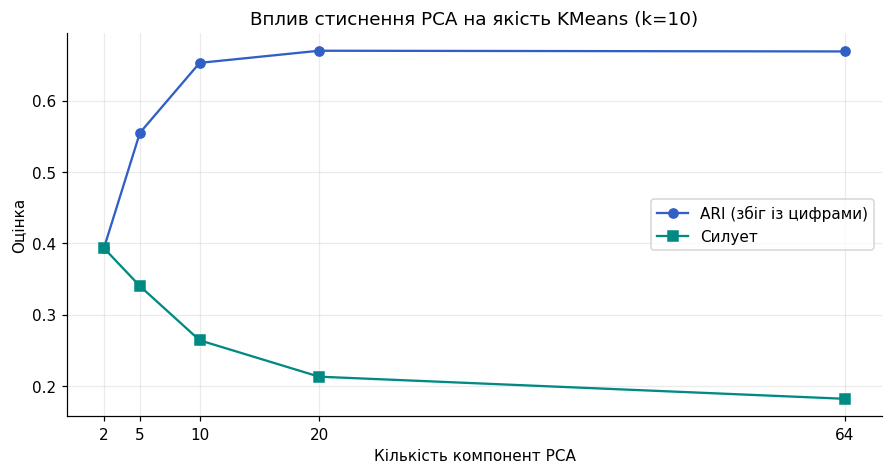

In [17]:
# ВАРІАНТ 5. Скільки пікселів насправді потрібно?
rows = []
for n_comp in [2, 5, 10, 20, 64]:
    if n_comp < 64:
        pca = PCA(n_components=n_comp, random_state=SEED)
        X_pca = pca.fit_transform(X_img)
        var_pct = round(100 * pca.explained_variance_ratio_.sum(), 1)
    else:
        X_pca = X_img
        var_pct = 100.0

    labels = KMeans(n_clusters=10, n_init=20, random_state=SEED).fit_predict(X_pca)
    rows.append({
        "компонент (PCA)": n_comp,
        "збережено дисперсії, %": var_pct,
        "силует": round(silhouette_score(X_pca, labels), 3),
        "ARI": round(adjusted_rand_score(digits.target, labels), 3),
    })

v5_table = pd.DataFrame(rows)
display(v5_table)

fig, ax = plt.subplots(figsize=(8, 4.2), constrained_layout=True)
ax.plot(v5_table["компонент (PCA)"], v5_table["ARI"], "o-", color="#315fc4", label="ARI (збіг із цифрами)")
ax.plot(v5_table["компонент (PCA)"], v5_table["силует"], "s-", color="#008a83", label="Силует")
ax.set(xlabel="Кількість компонент PCA", ylabel="Оцінка", title="Вплив стиснення PCA на якість KMeans (k=10)",
       xticks=[2, 5, 10, 20, 64])
ax.grid(alpha=0.25)
ax.legend()
plt.show()

### Висновок до індивідуального завдання (Варіант 5)
У межах індивідуального завдання було досліджено стиснення зображень (`8 × 8 = 64` пікселі) методом головних компонент (`PCA`) до `2, 5, 10, 20` і `64` чисел перед кластеризацією `KMeans (k = 10)`. При сильному стисненні до **2 компонент** втрачається більша частина інформації (зберігається лише `28.5%` дисперсії), тому якість групування низька (`ARI = 0.394`). Уже при **5 компонентах** (`54.5%` дисперсії) `ARI` зростає до `0.555`, а при **10 компонентах** (`73.8%` дисперсії) досягає **`ARI = 0.653`**, що майже не поступається результату на всіх 64 пікселях (`ARI = 0.669`). При **20 компонентах** (`89.4%` дисперсії) отримуємо **`ARI = 0.669`** — якість повністю збігається з повними 64 ознаками, але при вищому коефіцієнті силуету (`0.213` проти `0.182`). Отже, для кластеризації рукописних цифр достатньо **10–20 головних компонент** замість 64 вихідних пікселів (стиснення у 3–6 разів без втрати точності).